In [81]:
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets,transforms
from torchvision.transforms import ToTensor
from sklearn.metrics import ConfusionMatrixDisplay

In [82]:
from torchvision import transforms,datasets

In [83]:
format1 = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()   # dont ever fall for error here transform=transforms
]) 

In [84]:
train_data=datasets.ImageFolder(
    root=r'I:\archive\PetImages',
    transform=format1
)
test_data=datasets.ImageFolder(
    root=r'I:\archive\test_images',
    transform=format1
)

In [85]:
from torch.utils.data import DataLoader

In [86]:
train_dataloader=DataLoader(
    dataset=train_data,
    shuffle=True,
    batch_size=32
)

test_dataloader=DataLoader(
    dataset=test_data,
    shuffle=True,
    batch_size=32
)

In [87]:
images,labels =next(iter(train_dataloader))

In [88]:
len(images) , len(labels)

(32, 32)

In [89]:
labels.unique

<bound method Tensor.unique of tensor([0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0,
        0, 1, 1, 1, 0, 1, 0, 0])>

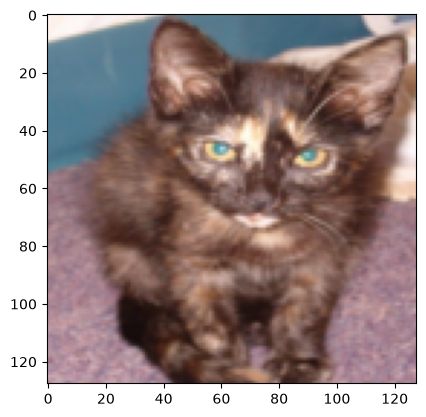

In [90]:
X=images[0]
import matplotlib.pyplot as plt
plt.imshow(X.permute(1,2,0))

In [91]:
# now data is ready time to build a model

In [92]:
class SpideyNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.convlayers=nn.Sequential(
            nn.Conv2d(
                in_channels=3,out_channels=128,padding=1,kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=128,out_channels=256,kernel_size=3,padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classificlayer=nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*32*32,256),
            nn.ReLU(),
            nn.Linear(256,2)
        )
    def forward(self,x):
        x=self.convlayers(x)
        x=self.classificlayer(x)
        return x 

In [93]:
device=torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

In [94]:
device

device(type='cuda')

In [95]:
model=SpideyNet().to(device)

In [96]:
model

SpideyNet(
  (convlayers): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classificlayer): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=262144, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=2, bias=True)
  )
)

In [97]:
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(lr=0.001,params=model.parameters())

In [98]:
def trainingloop(model:torch.nn.Module,
                loss_function:torch.nn.Module,
                 optimizer:torch.nn.Module,
                 device:torch.device=device,
                 dataloader=torch.utils.data.DataLoader):
    model.train()
    train_loss=0
    for batch,(X,y) in enumerate(dataloader):
        X,y=X.to(device),y.to(device)
        # X=X.permute(0,2,3,1)
        pred=model(X)
        loss=loss_function(pred,y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss +=loss
    train_loss /=len(dataloader)

    if epoch % 1 ==0:
        print(f'epoch -> {epoch} , train loss ->{train_loss.item()}')
    

In [99]:
import tqdm.auto as tqdm

In [ ]:
epoch=3
for epoch in tqdm.tqdm(range(epoch)):
    trainingloop(model=model,loss_function=loss_function,optimizer=optimizer,device=device,dataloader=train_dataloader)

  0%|          | 0/3 [00:00<?, ?it/s]

In [ ]:
torch.save(model.state_dict(),r'C:/Users/vivek kumbhar/Desktop/DogsvsCat/model/modeldogvscatspideynet.pth')